### Phase 3 (Data Preparation)

In [1]:
import os
from dotenv import load_dotenv
from pathlib import Path
import duckdb
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
#from sklearn.model_selection import GroupKFold
from sklearn.model_selection import train_test_split
import numpy as np
import requests

### Ladataan projektin juuren .env-tiedosto

Projektin juuressa sijaitseva `.env`-tiedosto sisältää käyttäjäkohtaiset asetukset,
joita ei jaeta Gitissä — kuten `DATA_PATH`, joka osoittaa paikalliseen data-kansioon.
Näin koodiin ei tarvitse kovakoodata tiedostopolkuja ja jokainen kehittäjä voi käyttää
omaa sijaintiaan.

In [2]:
load_dotenv()

# Luetaan datakansion polku .env-tiedostosta
DATA_PATH = Path(os.getenv("DATA_PATH"))

### Ladataan ja esikäsitellään data – tallennetaan välivaiheen parquet

Tämä skripti muuntaa raakamuotoisen CSV-tiedoston (10GB) parquet-muotoon.
Parquet on sarakeperusteinen tiedostoformaatti joka:
  - Pakkaa datan pienemmäksi (10GB → ~3GB)
  - Mahdollistaa yksittäisten sarakkeiden lataamisen ilman koko tiedoston lukemista
  - On huomattavasti nopeampi ladata kuin CSV
  
DuckDB hoitaa muunnoksen suoraan levyltä ilman että koko CSV ladataan muistiin, mikä mahdollistaa 10GB tiedoston käsittelyn myös pienellä RAM-määrällä.


In [3]:
# =============================================================================
# ESIKÄSITELTY VÄLITALLENNE: PARQUET
# =============================================================================
# Tarkistetaan onko esikäsitelty parquet jo olemassa.
# Jos on → ladataan suoraan, ohitetaan koko esikäsittely.
# Jos ei → luodaan ensin parquet CSV:stä, ajetaan esikäsittely ja tallennetaan.
# =============================================================================

raw_path     = DATA_PATH / "used_cars_data.parquet"
sample_path_csv = DATA_PATH / "used_cars_data_sample.csv"
cleaned_path = DATA_PATH / "used_cars_data_cleaned.parquet"

# Luodaan raakadata-parquet CSV:stä jos sitä ei ole
if not raw_path.exists():
    print("Luodaan parquet CSV:stä...")
    duckdb.execute(f"""
        COPY (
            SELECT * FROM read_csv_auto('{str(DATA_PATH / "used_cars_data.csv")}',
                types={{'dealer_zip': 'VARCHAR'}}
            )
        ) TO '{str(raw_path)}'
        (FORMAT PARQUET)
    """)
    print(f"Valmis! Tallennettu: {raw_path}")


# Sample CSV raakadatasta ennen suodattamista / esikäsittelyä
if not sample_path_csv.exists():
    print("Luodaan raakadatasta sample (10k riviä CSV-muodossa)...")

    duckdb.execute(f"""
        COPY (
            SELECT *
            FROM read_parquet('{str(raw_path)}')
            USING SAMPLE 10000 ROWS
        ) TO '{str(sample_path_csv)}'
        (FORMAT CSV, HEADER TRUE)
    """)

    print(f"Sample tallennettu CSV:nä: {sample_path_csv}")
else:
    print("Sample CSV löytyi valmiina - ei luoda uudelleen.")


# Ladataan esikäsitelty data jos olemassa, muuten ajetaan esikäsittely
if cleaned_path.exists():
    df = pl.read_parquet(cleaned_path)
    print(f"Ladattu välivaiheen tiedosto: {df.shape[0]:,} riviä, {df.shape[1]} saraketta")
else:
    df = pl.scan_parquet(raw_path)

    # Tarkistus raakadatalle
    # df.describe()

    df_lazy = (
        df
        .select([
            "body_type", "engine_displacement", "engine_type",
            "mileage", "fuel_type", "horsepower", "latitude", "longitude",
            "major_options", "make_name", "model_name", "price",
            "transmission_display", "wheel_system", "year", "listed_date", "length"
        ])
        .filter(pl.col("price").is_between(1000, 150000))
        .filter((pl.col("mileage") < 500000) | pl.col("mileage").is_null())
        .filter(pl.col("year").is_between(1990, 2023))
        .filter(pl.col("latitude").is_not_null()) # Geo-featuret vaativat koordinaatit
        .filter(pl.col("longitude").is_not_null())
        .unique() # Poistetaan duplikaatit
    )
    df = df_lazy.collect()
    df.write_parquet(cleaned_path)
    
    print(f"Tallennettu: {df.shape[0]:,} riviä, {df.shape[1]} saraketta")

Sample CSV löytyi valmiina - ei luoda uudelleen.
Ladattu välivaiheen tiedosto: 2,851,658 riviä, 18 saraketta


### Puuttuvien arvojen Heatmap ennen käsittelyä

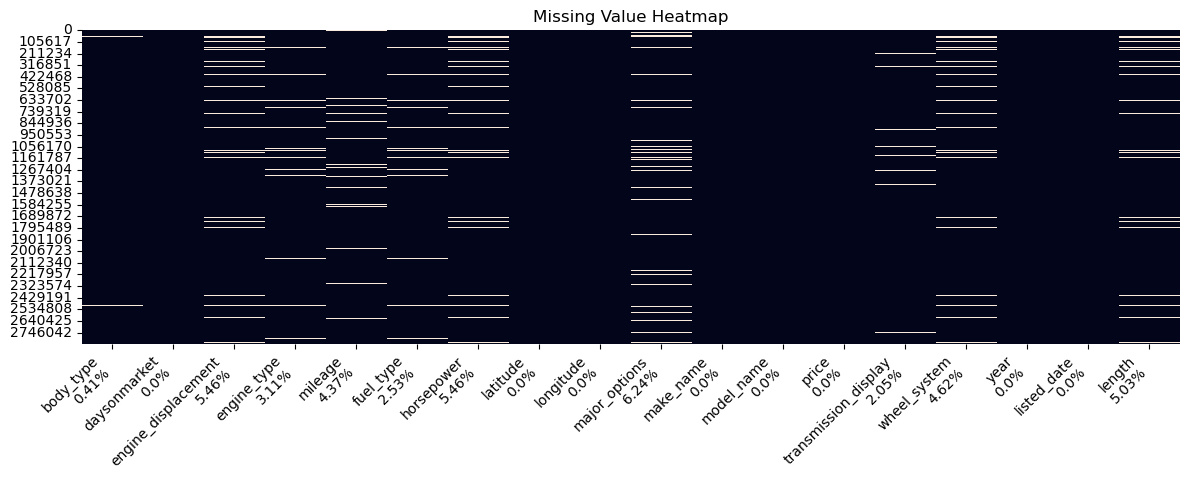

2851658

In [4]:
# --- Muutetaan Polars → Pandas vain heatmapin ajaksi ---
pdf = df.to_pandas()

missing_pct = (pdf.isnull().mean() * 100).round(2)

plt.figure(figsize=(12,5))
ax = sns.heatmap(pdf.isnull(), cbar=False)

# lisää prosentit x‑akselin labeleihin
new_labels = [
    f"{col}\n{missing_pct[col]}%" for col in pdf.columns
]

ax.set_xticklabels(new_labels, rotation=45, ha="right")
plt.title("Missing Value Heatmap")
plt.tight_layout()
plt.show()

# --- Palautetaan Pandas → Polars ---
df = pl.from_pandas(pdf)

df.height

### Puuttuvien arvojen imputointi

| # | Sarake | Menetelmä |
|---|--------|-----------|
| 1 | Horsepower | Mediaani merkin + mallin mukaan |
| 2 | Mileage | Mediaani vuosimallin mukaan |
| 3 | Fuel Type | Yleisin arvo: make+model+year → make+model → make |
| 4 | Body Type | Yleisin arvo: make+model → make |
| 5 | Engine Type | Yleisin arvo: make+model → make |
| 6 | Transmission | Yleisin arvo: make+model → make |
| 7 | Wheel System | Yleisin arvo: make+model → make |
| 8 | Engine Displacement | Mediaani merkin + mallin mukaan. Poikkeus: Fuel Type 'Electric' → 0 |
| 9 | Length | YMediaani make+model → make → body_type + length_missing‑flag |
| 10 | Major Options | Täytetään tyhjällä listalla `[]` |

In [5]:
# Muutetaan sarakkeet varmasti oikeisiin datatyyppeihin (Polars ei tee tätä automaattisesti → ehkäisee virheitä)
df = df.with_columns([
    pl.col("year").cast(pl.Int64),
    pl.col("mileage").cast(pl.Float64),
    pl.col("horsepower").cast(pl.Float64),
    pl.col("fuel_type").cast(pl.Utf8),
    pl.col("engine_type").cast(pl.Utf8),
])


# ══════ 1. HORSEPOWER  make+model → make median ══════
# Lasketaan mediaani merkin ja mallin mukaan.
hp_median = (
    df.group_by(["make_name", "model_name", "year"])
      .agg(pl.col("horsepower").median().alias("hp_med"))
)

# Liitetään medianit takaisin dataan ja täytetään puuttuvat arvot.
df = (
    df.join(hp_median, on=["make_name", "model_name", "year"], how="left")
      .with_columns(pl.col("horsepower").fill_null(pl.col("hp_med")))
      .drop("hp_med")   # poistetaan apusarakkeena käytetty median-sarake
)



# ══════ 2. MILEAGE  year → median ══════
# Luodaan binäärinen flagi joka kertoo, oliko mileage alun perin puuttuva. Tätä voi käyttää myöhemmin mallissa signaalina datan laadusta.
df = df.with_columns([
    pl.col("mileage").is_null().cast(pl.Int8).alias("mileage_missing")
])

# Lasketaan vuosimallikohtainen median-ajokilometrimäärä.
mile_median = (
    df.group_by("year")
      .agg(pl.col("mileage").median().alias("mile_med"))
)

# Liitetään median mukaan vuosimallin perusteella ja täytetään puuttuvat kilometrit.
df = (
    df.join(mile_median, on="year", how="left")
      .with_columns(pl.col("mileage").fill_null(pl.col("mile_med")))
      .drop("mile_med")   # poistetaan apusarakkeena käytetty median-sarake
)


# ══════ 3. FUEL TYPE  make+model+year → make+model → make ══════
# Taso 1: Täytetään puuttuvat polttoainetyypit mallivuosikohtaisesti (make + model + year) - käytetään yleisintä polttoainetyyppiä jokaiselle yhdistelmälle.
mode_lvl1 = (
    df.group_by(["make_name", "model_name", "year"])
      .agg(pl.col("fuel_type").mode().alias("fuel_mode"))
)

df = df.join(mode_lvl1, on=["make_name", "model_name", "year"], how="left")

df = df.with_columns([
    # Jos fuel_type puuttuu, täytetään se ryhmän yleisimmällä arvolla
    pl.col("fuel_type").fill_null(pl.col("fuel_mode").list.get(0))
]).drop("fuel_mode")


# Taso 2: Jos vuosikohtainen tieto ei riitä, käytetään make + model -tason yleisintä polttoainetyyppiä.
mode_lvl2 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("fuel_type").mode().alias("fuel_mode"))
)

df = df.join(mode_lvl2, on=["make_name", "model_name"], how="left")

df = df.with_columns([
    pl.col("fuel_type").fill_null(pl.col("fuel_mode").list.get(0))
]).drop("fuel_mode")


# Taso 3: Viimeisenä vaiheena käytetään automerkin (make_name) yleisintä polttoainetyyppiä.
mode_lvl3 = (
    df.group_by("make_name")
      .agg(pl.col("fuel_type").mode().alias("fuel_mode"))
)

df = df.join(mode_lvl3, on="make_name", how="left")

df = df.with_columns([
    pl.col("fuel_type").fill_null(pl.col("fuel_mode").list.get(0))
]).drop("fuel_mode")


# ══════ 4. BODY TYPE  make+model → make ══════
# Lasketaan merkki–mallikohtainen yleisin korimalli (body_type) ja täytetään puuttuvat arvot sillä.
# Taso 1 (make + model)
body_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("body_type").mode().alias("body_mode"))
)
df = (
    df.join(body_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("body_type").fill_null(pl.col("body_mode").list.get(0)))
      .drop("body_mode")
)

# Taso 2 (make)
body_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("body_type").mode().alias("body_mode"))
)
df = (
    df.join(body_lvl2, on="make_name", how="left")
      .with_columns(pl.col("body_type").fill_null(pl.col("body_mode").list.get(0)))
      .drop("body_mode")
)



# ══════ 5. ENGINE TYPE  make+model → make ══════
eng_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("engine_type").mode().alias("eng_mode"))
)
df = (
    df.join(eng_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("engine_type").fill_null(pl.col("eng_mode").list.get(0)))
      .drop("eng_mode")
)

eng_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("engine_type").mode().alias("eng_mode"))
)
df = (
    df.join(eng_lvl2, on="make_name", how="left")
      .with_columns(pl.col("engine_type").fill_null(pl.col("eng_mode").list.get(0)))
      .drop("eng_mode")
)


# ══════ 6. TRANSMISSION  make+model → make ══════
trans_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("transmission_display").mode().alias("trans_mode"))
)
df = (
    df.join(trans_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("transmission_display").fill_null(pl.col("trans_mode").list.get(0)))
      .drop("trans_mode")
)
trans_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("transmission_display").mode().alias("trans_mode"))
)
df = (
    df.join(trans_lvl2, on="make_name", how="left")
      .with_columns(pl.col("transmission_display")
                    .fill_null(pl.col("trans_mode").list.get(0)))
      .drop("trans_mode")
)

# Poistetaan rivi jota ei saatu imputoitua
df = df.drop_nulls(subset=["transmission_display"])

# ══════ 7. WHEEL SYSTEM  make+model → make ══════
# Taso 1: make + model
wheel_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("wheel_system").mode().alias("wheel_mode"))
)

df = (
    df.join(wheel_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("wheel_system")
          .fill_null(pl.col("wheel_mode").list.get(0))
      )
      .drop("wheel_mode")
)

# Taso 2: fallback make
wheel_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("wheel_system").mode().alias("wheel_mode"))
)

df = (
    df.join(wheel_lvl2, on="make_name", how="left")
      .with_columns(pl.col("wheel_system")
          .fill_null(pl.col("wheel_mode").list.get(0))
      )
      .drop("wheel_mode")
)

# ══════ 8. ENGINE DISPLACEMENT  make+model → median ══════
# Sähköautojen iskutilavuus ei ole relevantti → asetetaan nollaksi
# Määritellään is_ev -flag
df = df.with_columns([
    # EV-flag ML-mallia ja jatkokäsittelyä varten
    (pl.col("fuel_type") == "Electric")
        .cast(pl.Int8)
        .alias("is_ev"),

    # Engine displacement → 0 EV:ille
    pl.when(pl.col("fuel_type") == "Electric")
        .then(0.0)
        .otherwise(pl.col("engine_displacement"))
        .alias("engine_displacement")
])

# Lasketaan merkki–mallikohtainen median-moottorin iskutilavuus imputointia varten.
disp_median = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("engine_displacement").median().alias("disp_med"))
)

df = (
    df.join(disp_median, on=["make_name", "model_name"], how="left")
      .with_columns(pl.col("engine_displacement").fill_null(pl.col("disp_med")))
      .drop("disp_med")
)

# ══════ 9. LENGTH (auton pituus) – model → make → body_type ══════

# Luo missing flag
df = df.with_columns(
    pl.col("length").is_null().cast(pl.Int8).alias("length_missing")
)

# Taso 1 - model-level median length
length_lvl1 = (
    df.group_by(["make_name", "model_name"])
      .agg(pl.col("length").median().alias("len_med"))
)

df = (
    df.join(length_lvl1, on=["make_name", "model_name"], how="left")
      .with_columns(
          pl.col("length").fill_null(pl.col("len_med"))
      )
      .drop("len_med")
)

# Taso 2 - make-level median length
length_lvl2 = (
    df.group_by("make_name")
      .agg(pl.col("length").median().alias("len_med"))
)

df = (
    df.join(length_lvl2, on="make_name", how="left")
      .with_columns(
          pl.col("length").fill_null(pl.col("len_med"))
      )
      .drop("len_med")
)

# Taso 3 - body_type-level median (fallback)
length_lvl3 = (
    df.group_by("body_type")
      .agg(pl.col("length").median().alias("len_med"))
)

df = (
    df.join(length_lvl3, on="body_type", how="left")
      .with_columns(
          pl.col("length").fill_null(pl.col("len_med"))
      )
      .drop("len_med")
)

# ══════ 10. MAJOR OPTIONS  fill [] ══════
df = df.with_columns([
    pl.col("major_options").fill_null("[]")
])

before = df.height


# Poistetaan rivit joille imputointi ei riittänyt - liian harvinainen make+model-yhdistelmä
for col in ["engine_displacement", "length", "horsepower"]:
    n = df.filter(pl.col(col).is_null()).height
    print(f"  {col}: {n:,} null-riviä poistetaan")

df = df.drop_nulls(subset=["engine_displacement", "length", "horsepower"])
after = df.height
print(f"\nPoistettu yhteensä {before - after:,} riviä ({(before - after) / before * 100:.2f}%)")
print(f"Jäljellä {after:,} riviä")


print("Imputoinnit suoritettu.")


  engine_displacement: 3,623 null-riviä poistetaan
  length: 143,510 null-riviä poistetaan
  horsepower: 41,276 null-riviä poistetaan

Poistettu yhteensä 143,713 riviä (5.04%)
Jäljellä 2,707,943 riviä
Imputoinnit suoritettu.


### Puuttuvien arvojen Heatmap käsittelyn jälkeen

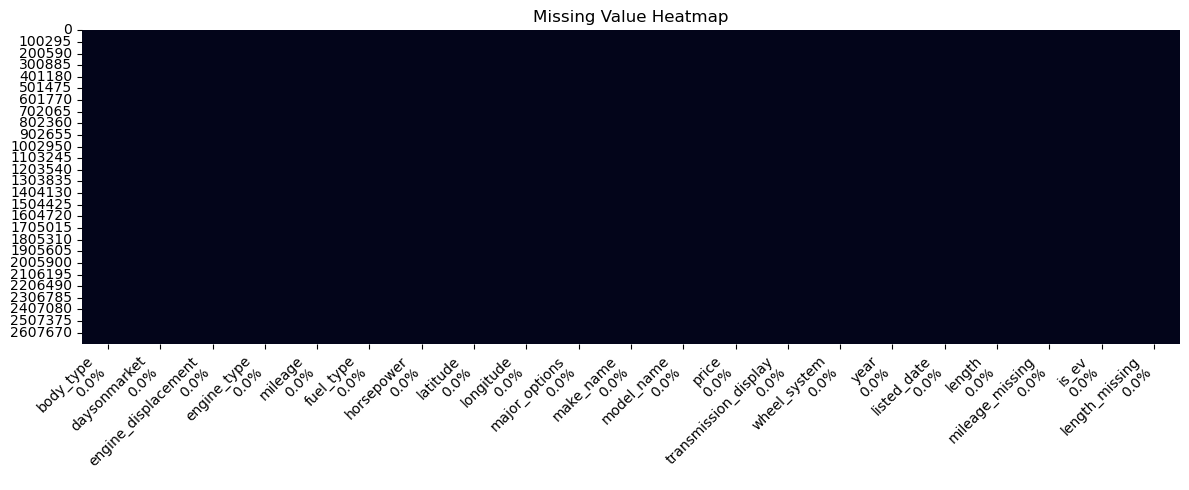

In [6]:
# --- Muutetaan Polars → Pandas vain heatmapin ajaksi ---
pdf = df.to_pandas()

missing_pct = (pdf.isnull().mean() * 100).round(2)

plt.figure(figsize=(12,5))
ax = sns.heatmap(pdf.isnull(), cbar=False)

# lisää prosentit x‑akselin labeleihin
new_labels = [
    f"{col}\n{missing_pct[col]}%" for col in pdf.columns
]

ax.set_xticklabels(new_labels, rotation=45, ha="right")
plt.title("Missing Value Heatmap")
plt.tight_layout()
plt.show()

# --- Palautetaan Pandas → Polars ---
df = pl.from_pandas(pdf)

In [7]:
df.describe()

statistic,body_type,daysonmarket,engine_displacement,engine_type,mileage,fuel_type,horsepower,latitude,longitude,major_options,make_name,model_name,price,transmission_display,wheel_system,year,listed_date,length,mileage_missing,is_ev,length_missing
str,str,f64,f64,str,f64,str,f64,f64,f64,str,str,str,f64,str,str,f64,str,str,f64,f64,f64
"""count""","""2707943""",2.707943e6,2.707943e6,"""2707943""",2.707943e6,"""2707943""",2.707943e6,2.707943e6,2.707943e6,"""2707943""","""2707943""","""2707943""",2.707943e6,"""2707943""","""2707940""",2.707943e6,"""2707943""","""2707943""",2.707943e6,2.707943e6,2.707943e6
"""null_count""","""0""",0.0,0.0,"""0""",0.0,"""0""",0.0,0.0,0.0,"""0""","""0""","""0""",0.0,"""0""","""3""",0.0,"""0""","""0""",0.0,0.0,0.0
"""mean""",null,76.640307,2983.905644,null,31207.024879,null,249.072694,37.023375,-90.515034,null,null,null,29289.263299,null,null,2017.722343,"""2020-06-25 20:44:47.320000""",null,0.042922,3.6928e-7,0.0
"""std""",null,108.409151,1347.301188,null,44705.88737,null,89.594693,4.978561,13.810857,null,null,null,16347.426301,null,null,3.58786,null,null,0.202681,0.000608,0.0
"""min""","""Convertible""",0.0,0.0,"""H4""",0.0,"""Biodiesel""",55.0,18.3467,-157.928,"""['101A Mid Equipment Group', '…","""AM General""","""1 Series""",1000.0,"""1-Speed Automatic""","""4WD""",1990.0,"""2010-11-29 00:00:00""","""--""",0.0,0.0,0.0
"""25%""",null,15.0,2000.0,null,6.0,null,175.0,33.5163,-96.99,null,null,null,17995.0,null,null,2017.0,"""2020-06-20 00:00:00""",null,0.0,0.0,0.0
"""50%""",null,36.0,2500.0,null,10179.0,null,245.0,37.9736,-87.1188,null,null,null,26043.0,null,null,2019.0,"""2020-08-06 00:00:00""",null,0.0,0.0,0.0
"""75%""",null,83.0,3600.0,null,43933.0,null,301.0,41.0246,-80.3832,null,null,null,37850.0,null,null,2020.0,"""2020-08-27 00:00:00""",null,0.0,0.0,0.0
"""max""","""Wagon""",3573.0,8400.0,"""W8""",434718.0,"""Propane""",808.0,61.2031,-66.0785,"""[]""","""smart""","""xD""",150000.0,"""Manual""","""RWD""",2021.0,"""2020-09-13 00:00:00""","""294.1 in""",1.0,1.0,0.0


### Varuste-flagien lisääminen
22 tärkeintä varustetta valittu esiintymisen ja toiminnallisuuden perusteella

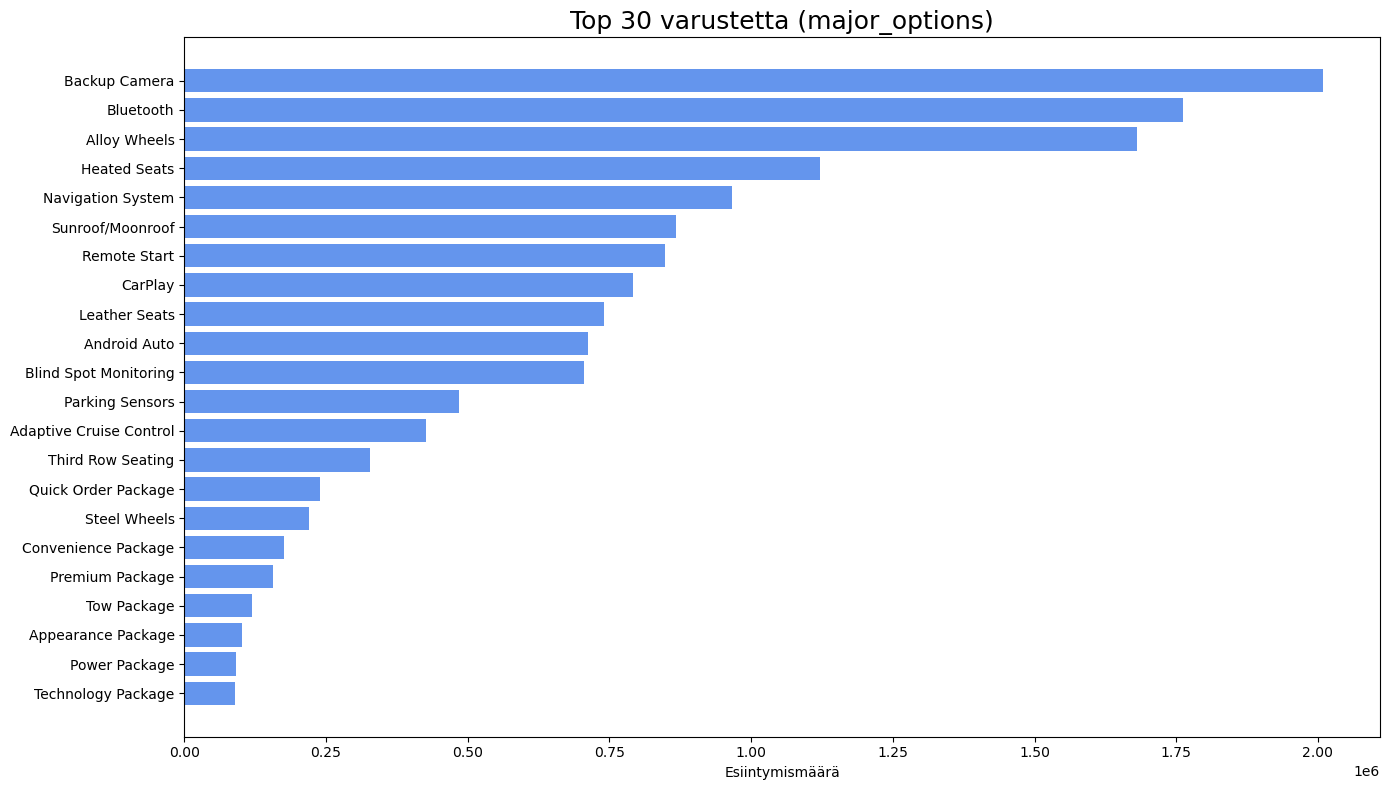

In [8]:
# Pilkotaan varusteet listaksi
df_options = (
    df.select(
        pl.col("major_options")
            .str.replace_all(r"\[|\]|'", "")     # poista hakasulkeet ja ' merkit
            .str.split(",")                      # pilko listaksi
            .list.explode()                      # yksi varuste per rivi
            .str.strip_chars()                   # trimmaa whitespace
            .alias("option")
    )
    .group_by("option")
    .len()
    .sort("len", descending=True)
).to_pandas()

# df_options on jo Pandas-DataFrame, käytetään sellaisenaan
pdf = df_options.copy()

# Poistetaan tyhjät rivit
pdf = pdf[pdf['option'].notna() & (pdf['option'] != '')]

# Otetaan top 30
pdf_top = pdf.head(22)

plt.figure(figsize=(14, 8))
plt.barh(pdf_top["option"], pdf_top["len"], color="cornflowerblue")
plt.gca().invert_yaxis()
plt.title("Top 30 varustetta (major_options)", fontsize=18)
plt.xlabel("Esiintymismäärä")
plt.tight_layout()
plt.show()

In [9]:
feature_map = {
    # ══════ Perusvarusteet (TOP 12) ══════
    "opt_backup_camera":      ["Backup Camera", "Rearview Camera"],
    "opt_bluetooth":          ["Bluetooth"],
    "opt_alloy_wheels":       ["Alloy Wheels"],
    "opt_heated_seats":       ["Heated Seats"],
    "opt_navigation":         ["Navigation System", "Navigation"],
    "opt_sunroof":            ["Sunroof", "Moonroof"],
    "opt_remote_start":       ["Remote Start"],
    "opt_carplay":            ["CarPlay"],
    "opt_android_auto":       ["Android Auto"],
    "opt_leather_seats":      ["Leather Seats"],
    "opt_blind_spot":         ["Blind Spot"],
    "opt_parking_sensors":    ["Parking Sensors", "Park Assist"],

    # ══════ Turvallisuus / ajaminen ══════
    "opt_adaptive_cruise":    ["Adaptive Cruise"],
    "opt_lane_departure":     ["Lane Departure"],
    "opt_cross_traffic":      ["Cross-Traffic"],
    "opt_third_row":          ["Third Row"],
    "opt_tow_package":        ["Tow Package"],

    # ══════ Mukavuus / premium ══════
    "opt_multi_zone":         ["Multi Zone Climate"],
    "opt_premium_audio":      ["Premium Audio", "Bose", "Harman", "Meridian"],
    "opt_cold_weather":       ["Cold Weather Package"],
    "opt_heat_package":       ["Heat Package"],
    "opt_off_road":           ["Off Road Package"],
}

exprs = []

# Luodaan flagit
for col_name, patterns in feature_map.items():
    e = pl.lit(False)
    for p in patterns:
        e = e | pl.col("major_options").str.contains(p, literal=False)
    exprs.append(e.cast(pl.Int8).alias(col_name))

df = df.with_columns(exprs)

print("Lisätty varusteflagit:", list(feature_map.keys()))

Lisätty varusteflagit: ['opt_backup_camera', 'opt_bluetooth', 'opt_alloy_wheels', 'opt_heated_seats', 'opt_navigation', 'opt_sunroof', 'opt_remote_start', 'opt_carplay', 'opt_android_auto', 'opt_leather_seats', 'opt_blind_spot', 'opt_parking_sensors', 'opt_adaptive_cruise', 'opt_lane_departure', 'opt_cross_traffic', 'opt_third_row', 'opt_tow_package', 'opt_multi_zone', 'opt_premium_audio', 'opt_cold_weather', 'opt_heat_package', 'opt_off_road']


### Varusteflagien korrelaatio-heatmap

Varusteflageissa näkyy kolme selkeää ryhmää:
(1) modernit infotainment‑varusteet (CarPlay–Android Auto, r=0.92),
(2) premium‑varusteet (leather seats, heated seats, sunroof, navigation; r≈0.4),
(3) turvallisuus‑/ajoturva‑varusteet (blind spot, parking sensors, backup camera; r≈0.3).

Korrelaatiot näyttävät, että osa varusteista esiintyy samoissa autoissa hieman tavallista useammin (esim. lämmitettävät penkit ja nahkaverhoilu), mutta mikään varuste ei kulje toisen mukana niin vahvasti, että ne olisivat käytännössä sama asia.

Tämä on hyvä merkki: se tarkoittaa, että jokainen varusteflagi tuo mallille omaa erillistä lisätietoa, eikä mukana ole päällekkäisiä tai turhia varusteita. Eli nämä varusteet antavat mallille oikeaa hyödyllistä signaalia, eivät pelkkää kohinaa tai “melua”.

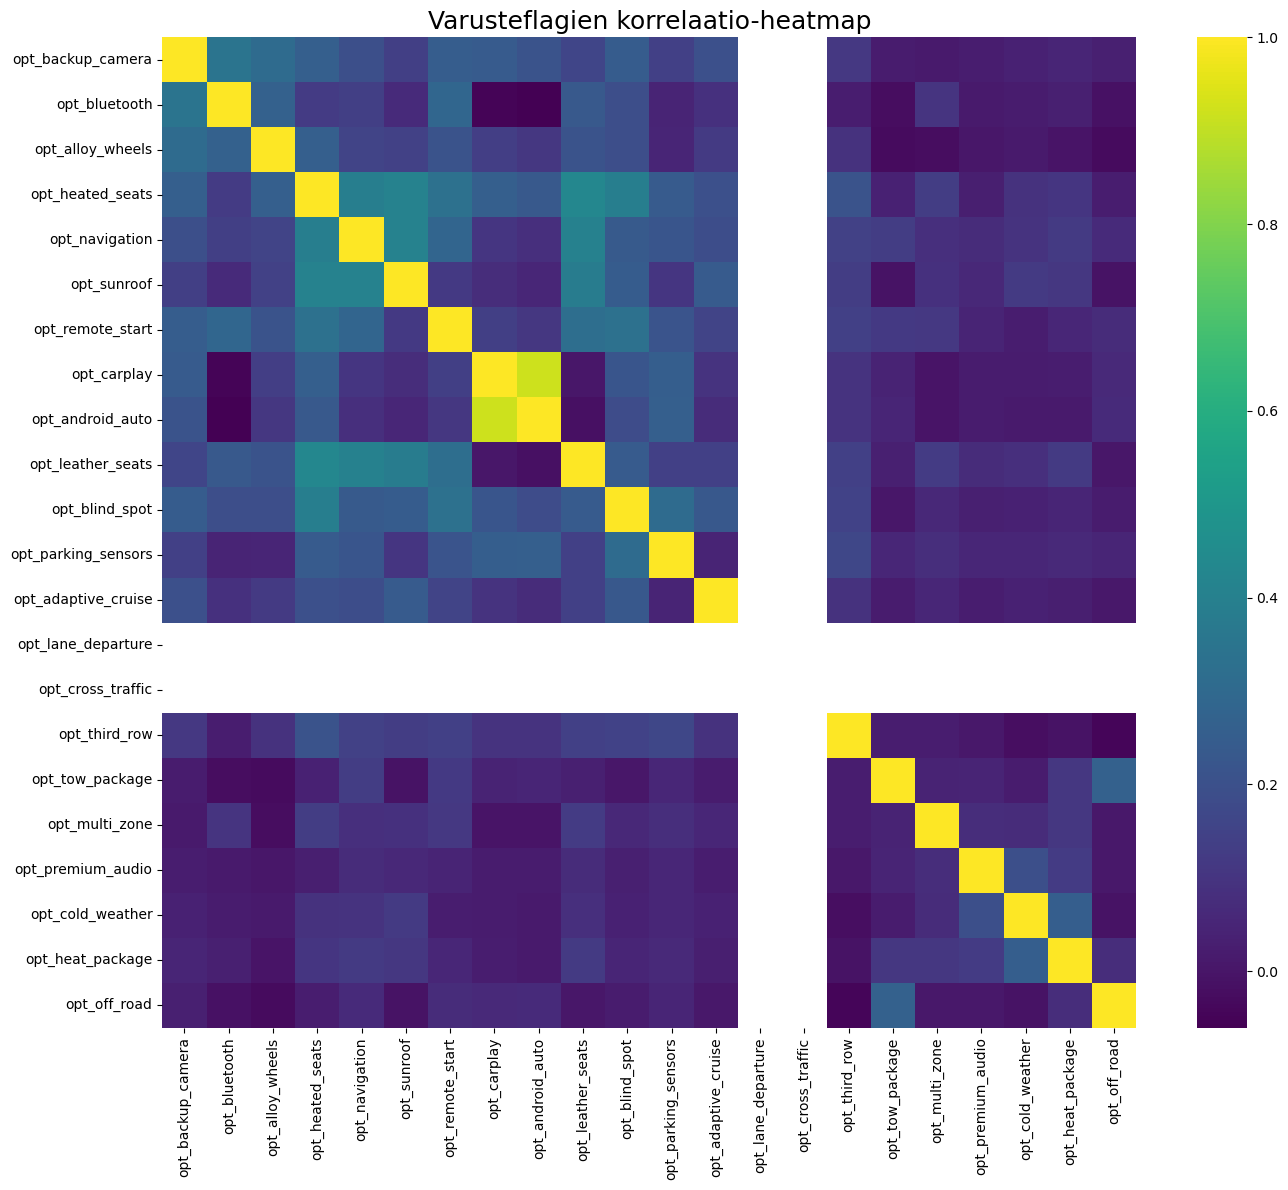

In [10]:

flag_cols = [col for col in df.columns if col.startswith("opt_")]

pdf_flags = df[flag_cols].to_pandas()

plt.figure(figsize=(14, 12))
sns.heatmap(pdf_flags.corr(), cmap="viridis", annot=False)
plt.title("Varusteflagien korrelaatio-heatmap", fontsize=18)
plt.tight_layout()
plt.show()


### Vaihteistoryhmittely (trans_group = Manual/Dual Clutch/CVT/Automatic)

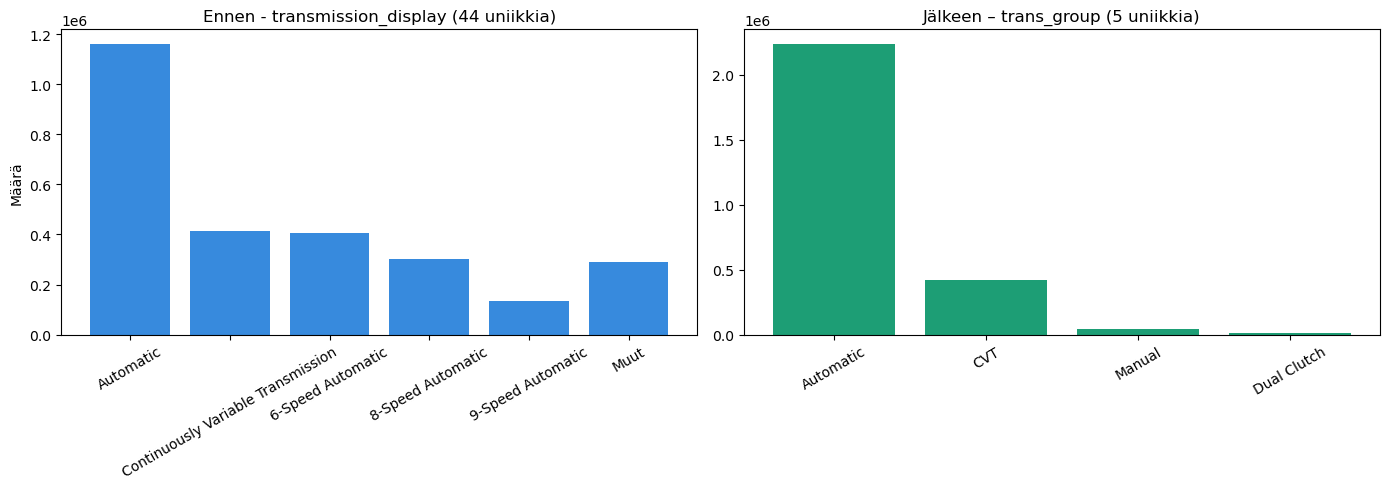

In [11]:
# ══════ Ryhmitellään 44 vaihteistotyyppiä 5 pääkategoriaan tekstihaun perusteella ══════

df = df.with_columns(
    pl.when(pl.col("transmission_display").str.contains("Manual", literal=False))
        .then(pl.lit("Manual"))
    .when(pl.col("transmission_display").str.contains("Dual Clutch", literal=False))
        .then(pl.lit("Dual Clutch"))
    .when(
        # CVT tunnetaan kahdella eri nimellä
        pl.col("transmission_display").str.contains("Continuously Variable", literal=False)
        | pl.col("transmission_display").str.contains("CVT", literal=False)
    )
        .then(pl.lit("CVT"))
    .when(pl.col("transmission_display").str.contains("Automatic", literal=False))
        .then(pl.lit("Automatic"))
    .otherwise(pl.lit("Unknown"))  # ei osuttu mihinkään kategoriaan
    .alias("trans_group")
)


# ══════ Vaihteistoryhmittelyn vaikutus - ennen ja jälkeen ══════

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ennen - otetaan top 5 ja loput yhdistetään "Muut"-kategoriaan
before = df["transmission_display"].value_counts().sort("count", descending=True).to_pandas()
before_top = before.head(5)
other = before.iloc[5:]["count"].sum()
before_plot = list(before_top["transmission_display"]) + ["Muut"]
before_vals = list(before_top["count"]) + [other]

axes[0].bar(before_plot, before_vals, color="#378ADD")
axes[0].set_title("Ennen - transmission_display (44 uniikkia)")
axes[0].set_ylabel("Määrä")
axes[0].tick_params(axis="x", rotation=30)

# Jälkeen - kaikki 5 ryhmää näkyviin sellaisenaan
after = df["trans_group"].value_counts().sort("count", descending=True).to_pandas()
axes[1].bar(after["trans_group"], after["count"], color="#1D9E75")
axes[1].set_title("Jälkeen – trans_group (5 uniikkia)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Kausiryhmittelyt

listed_date painottuu vuoteen 2020

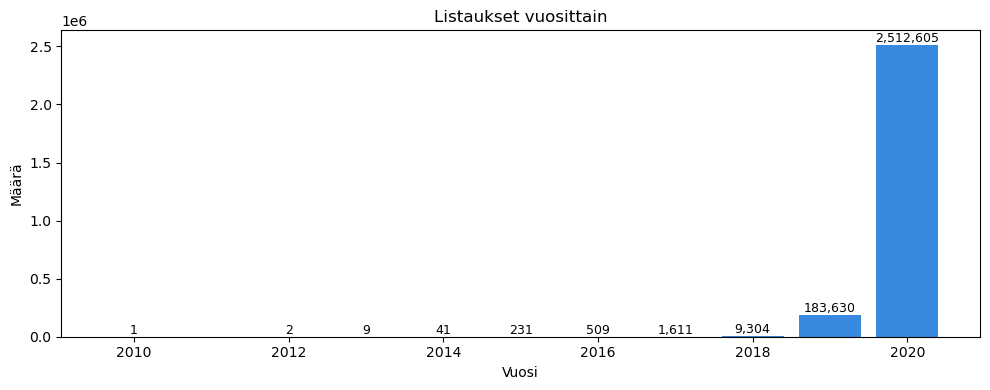

In [12]:
year_counts = (
    df.with_columns(
        pl.col("listed_date").dt.year().alias("listed_year")
    )
    .group_by("listed_year")
    .agg(pl.len().alias("count"))
    .sort("listed_year")
    .to_pandas()
)

plt.figure(figsize=(10, 4))
bars = plt.bar(year_counts["listed_year"], year_counts["count"], color="#378ADD")
plt.title("Listaukset vuosittain")
plt.xlabel("Vuosi")
plt.ylabel("Määrä")

# Lukema jokaisen pylvään yläpuolelle
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center", va="bottom", fontsize=9
    )

plt.tight_layout()
plt.show()

In [13]:
df = df.with_columns([
    # ══════ Vuodenaika kuukauden perusteella ══════
    pl.when(pl.col("listed_date").dt.month().is_in([12, 1, 2]))
        .then(pl.lit("Winter"))
    .when(pl.col("listed_date").dt.month().is_in([3, 4, 5]))
        .then(pl.lit("Spring"))
    .when(pl.col("listed_date").dt.month().is_in([6, 7, 8]))
        .then(pl.lit("Summer"))
    .otherwise(pl.lit("Fall"))
        .alias("listed_season"),

    # ══════ Kuukausi (1–12) ══════
    pl.col("listed_date").dt.month().alias("listed_month"),

    # ══════ Viikonpäivä (ma=0 ... su=6) ══════
    pl.col("listed_date").dt.weekday().alias("listed_weekday"),

    # ══════ Viikonloppu (la=5, su=6 → 1, muut → 0) ══════
    pl.when(pl.col("listed_date").dt.weekday().is_in([5, 6]))
        .then(pl.lit(1))
        .otherwise(pl.lit(0))
        .alias("is_weekend"),
])

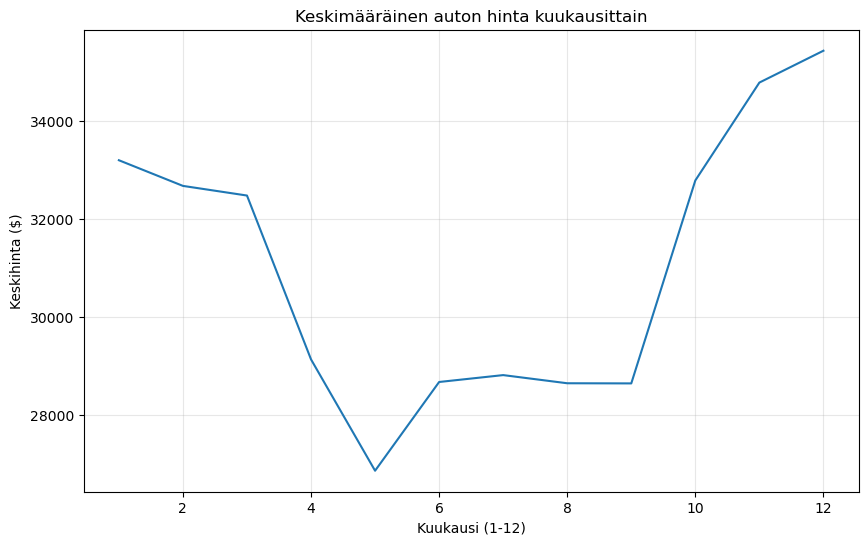

In [14]:

# Polars → Pandas
pdf = df.select(["listed_month", "price"]).to_pandas()

plt.figure(figsize=(10,6))
sns.lineplot(
    data=pdf,
    x="listed_month",
    y="price",
    estimator="mean",
    errorbar=None
)

plt.title("Keskimääräinen auton hinta kuukausittain")
plt.xlabel("Kuukausi (1-12)")
plt.ylabel("Keskihinta ($)")
plt.grid(alpha=0.3)
plt.show()


# Polars -> Pandas
pdf = df.to_pandas()

### Muut ryhmittelyt

In [15]:
# ══════ km_per_year – ajetut kilometrit suhteessa auton ikään ══════
# Jakamalla mileage auton iällä saadaan vuosittainen ajosuorite clip(lower_bound=1) estää jaon nollalla uusilla autoilla (listed_date.year == year)
df = df.with_columns([
    (pl.col("mileage") /
        (pl.col("listed_date").dt.year() - pl.col("year"))
          .clip(lower_bound=1)  # estää jakamisen nollalla
    ).alias("km_per_year")
])


# ══════ hp_per_liter (hv per litra) ══════
df = df.with_columns([
    (pl.col("horsepower") / pl.col("engine_displacement"))
        .alias("hp_per_liter")
])

# ══════ power_density (hv per pituusyksikkö) ══════
# Varmistetaan että length on numeerinen
df = df.with_columns([
    pl.col("length")
        .cast(pl.Utf8)
        .str.replace_all(r"[^0-9.]", "") # jätetään vain numerot ja piste
        .replace("", None) # tyhjät stringit → NULL
        .cast(pl.Float64)
        .alias("length")
])

df = df.with_columns([
    (pl.col("horsepower") / pl.col("length"))
        .alias("power_density")
])


# ══════ age_bin - auton ikä luokiteltuna ══════
df = df.with_columns([
    (pl.col("listed_date").dt.year() - pl.col("year")).alias("car_age")
])

df = df.with_columns([
    pl.when(pl.col("car_age") <= 3)
        .then(pl.lit("0-3v"))
    .when(pl.col("car_age") <= 5)
        .then(pl.lit("3-5v"))
    .when(pl.col("car_age") <= 8)
        .then(pl.lit("5-8v"))
    .otherwise(pl.lit("8+v"))
    .alias("age_bin")
])

# ══════ mileage_bin - kilometrit luokiteltuna ══════
df = df.with_columns([
    pl.when(pl.col("mileage") <= 15_000)
        .then(pl.lit("0-15k"))
    .when(pl.col("mileage") <= 50_000)
        .then(pl.lit("15k-50k"))
    .when(pl.col("mileage") <= 100_000)
        .then(pl.lit("50k-100k"))
    .otherwise(pl.lit("100k+"))
    .alias("mileage_bin")
])

# ══════ options_count - varusteiden määrä ══════
# Lasketaan pilkkujen määrä + 1 = varusteiden lukumäärä
# Tyhjä lista "[]" saa arvon 0
df = df.with_columns([
    pl.when(pl.col("major_options") == "[]")
        .then(pl.lit(0))
        .otherwise(pl.col("major_options").str.count_matches(",").add(1))
        .alias("options_count")
])

# ══════ luxury_brands - Luxury‑merkit ══════


luxury_brands = [
    "Audi",
    "BMW",
    "Mercedes-Benz",
    "Lexus",
    "Porsche",
    "Jaguar",
    "Land Rover",
    "Volvo",
    "Tesla",
    "Rolls-Royce",
    "Bentley",
    "Maserati",
    "Alfa Romeo",
    "Genesis",
    "Cadillac",
    "Lincoln",
    "Acura",
    "Infiniti",
]


df = df.with_columns([
    pl.col("make_name")
      .is_in(luxury_brands)
      .cast(pl.Int8)
      .alias("luxury_flag")
])

### Korrelaatioheatmap uusille teknisille featureille

Tehoon ja moottoriin liittyvät tekniset featuret selittävät auton hintaa vahvasti (horsepower, power_density), mutta eivät juuri myyntiajan vaihtelua. Sen sijaan kilometrit ja ajotahti (km_per_year) korreloivat selvästi hinnan laskun kanssa ja varusteiden määrä nostaa hintaa odotetusti. 

Myyntiaika on teknisille featureille vain heikosti lineaarinen ilmiö, mikä sopii yhteen markkinadynamiikan kanssa: myyntiaika määräytyy enemmän hinnoittelun, kysynnän ja makrotekijöiden mukaan kuin auton fyysisten ominaisuuksien.

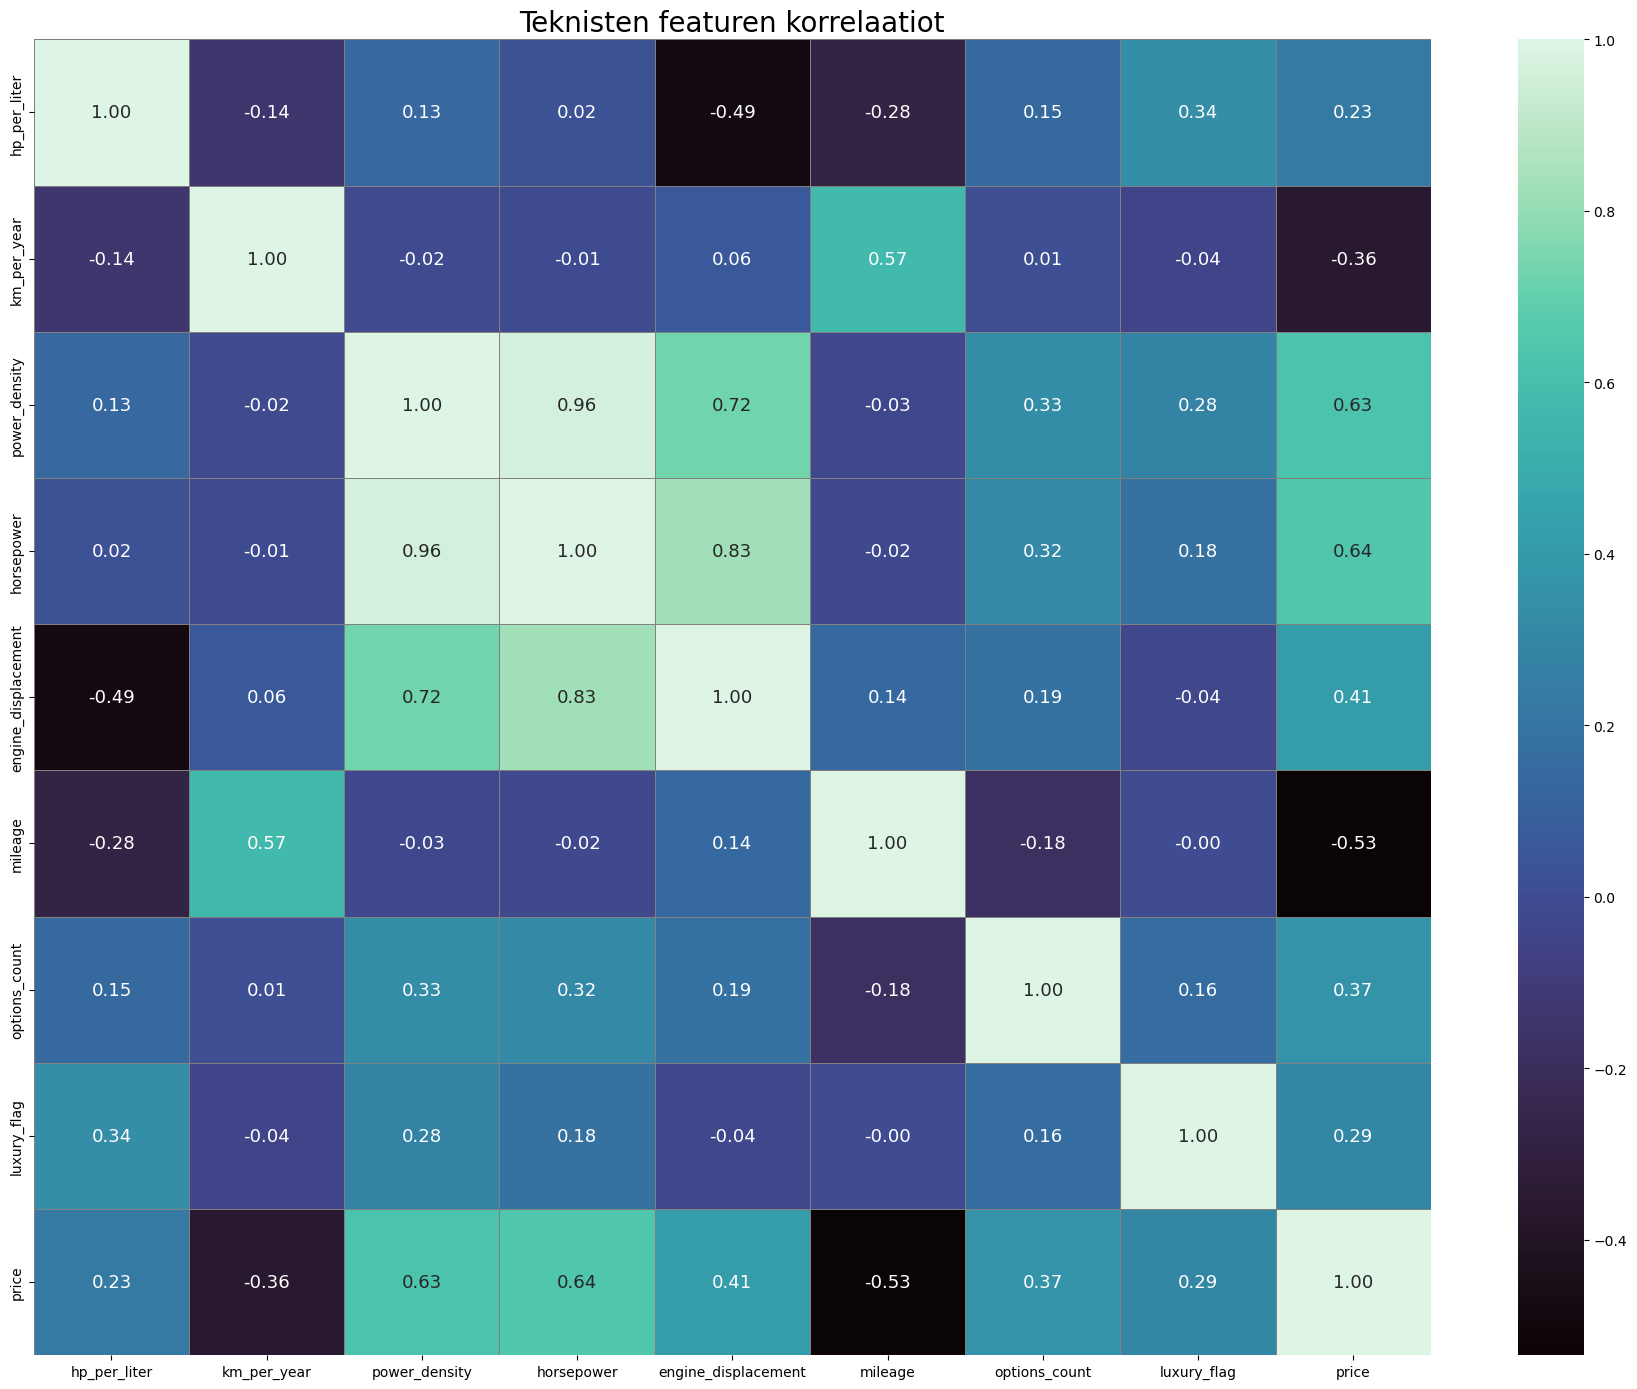

In [16]:
cols = [
    "hp_per_liter",
    "km_per_year",
    "power_density",
    "horsepower",
    "engine_displacement",
    "mileage",
    "options_count",
    "luxury_flag",
    "price"
]

plt.figure(figsize=(18, 14))
sns.heatmap(
    df.select(cols).to_pandas().corr(),
    annot=True,
    cmap="mako",
    fmt=".2f",
    linewidths=0.5,
    linecolor="gray",
    annot_kws={"size": 13}
)
plt.title("Teknisten featuren korrelaatiot", fontsize=20)
plt.tight_layout()
plt.show()

### Premium vs non‑premium vertailu (luxury_flag → price)

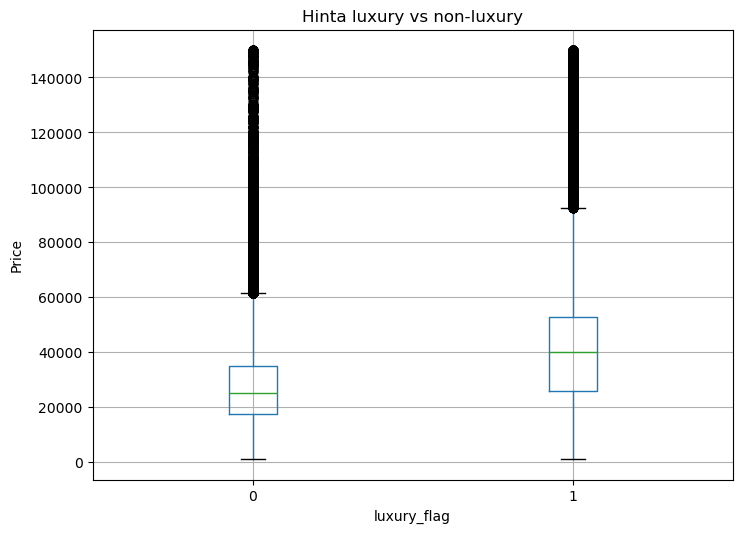

In [17]:
df.to_pandas().boxplot(column="price", by="luxury_flag", figsize=(8,6))
plt.title("Hinta luxury vs non-luxury")
plt.suptitle("")
plt.xlabel("luxury_flag")
plt.ylabel("Price")
plt.show()

### Geo-featuret

In [18]:
# Muutetaan Polars -> Pandas, koska geopandas tarvitsee Pandasia
pdf = df.to_pandas()
gdf = gpd.GeoDataFrame(
    pdf,
    geometry=gpd.points_from_xy(pdf["longitude"], pdf["latitude"]),
    crs="EPSG:4326"
)
# Ladataan USA:n piirikuntageometriat
counties = gpd.read_file(DATA_PATH / "cb_2023_us_county_500k.zip")[["GEOID", "NAME", "STATEFP", "geometry"]]
counties = counties.to_crs(gdf.crs)

# Spatial join (etäisyys = sisällä oleva piste)
gdf = gpd.sjoin(gdf, counties, how="left", predicate="within").drop(columns="index_right")

# Poistetaan US-territoriot (ei kuulu 50 osavaltioon)
territories = ["60", "66", "69", "72", "74", "78"]
gdf = gdf[~gdf["STATEFP"].isin(territories)]

# Poistetaan rivit joita ei saatu joinattua mihinkään countyyn
before = len(gdf)
gdf = gdf.dropna(subset=["GEOID"])
after = len(gdf)
removed = before - after

print(f"Poistettu rivejä: {removed:,}")
print(f"Rivejä joinin jälkeen: {len(gdf):,}")
print(f"Uniikkeja GEOID-piirikuntia: {gdf['GEOID'].nunique()}")
print(f"Uniikkeja osavaltioita: {gdf['STATEFP'].nunique()}")

# Palataan Polarsiin - geometry-sarake poistetaan
df = pl.from_pandas(gdf.drop(columns="geometry"))
print("Geotiedot lisätty (GEOID, NAME, STATEFP)")


Poistettu rivejä: 0
Rivejä joinin jälkeen: 2,707,840
Uniikkeja GEOID-piirikuntia: 2217
Uniikkeja osavaltioita: 50
Geotiedot lisätty (GEOID, NAME, STATEFP)


### Bensahintojen hakeminen ja liittäminen autolistings‑dataan (EIA API v2)

EIA = U.S. Energy Information Administration.

Yhdysvaltojen virallinen energia‑ ja polttoainehintojen datalähde

-> Joinissa käytettävä arvo on käytännössä kyseisen kuukauden VIIMEIN viikkohinta.

In [19]:
# Haetaan EIA API -avain ympäristömuuttujasta (.env).
API_KEY = os.getenv("EIA_API_KEY")

# Series ID: Yhdysvaltain keskihinta Regular Gasoline, viikkotasolla ($/gallon)
series_id = "PET.EMM_EPMR_PTE_NUS_DPG.W"
url = f"https://api.eia.gov/v2/seriesid/{series_id}?api_key={API_KEY}"

r = requests.get(url).json()
print("API keys:", r.keys())
data = r["response"]["data"]
df_gas = pd.DataFrame(data)

# Muutetaan hintasarake (value) float-muotoon ja aika datetimeksi
df_gas["gas_price"] = df_gas["value"].astype(float)
df_gas["date"] = pd.to_datetime(df_gas["period"])

# Kuukausiavain joinia varten (kuukauden 1. päivä)
df_gas["month_start"] = df_gas["date"].dt.to_period("M").dt.to_timestamp()

# Polarsiin (mukaan myös date, jotta voidaan valita kuukauden viimeinen viikko)
gas_pl = (
    pl.from_pandas(df_gas[["month_start", "date", "gas_price"]])
      .with_columns([
          pl.col("month_start").cast(pl.Datetime("ms")),
          pl.col("date").cast(pl.Datetime("ms")),
      ])
)

# TÄRKEÄÄ: EIA-data on viikkotasolla → aggregoidaan 1 rivi/kuukausi, jotta join ei monista autojen rivejä. Valitaan kuukauden viimeinen viikkohinta.
gas_pl_month = (
    gas_pl
    .sort("date")
    .group_by("month_start")
    .agg(pl.col("gas_price").last().alias("gas_price"))
)

# ══════ Joinataan auto-dataan ══════
# Luodaan auto-dataan yhteensopiva month_start (listauskuukauden alku)
df = df.with_columns(
    pl.col("listed_date")
      .dt.truncate("1mo")
      .cast(pl.Datetime("ms"))
      .alias("month_start")
)

before = df.height
df = df.join(gas_pl_month, on="month_start", how="left")
after = df.height
print("Rivejä ennen gas-joinia:", before)
print("Rivejä jälkeen gas-joinin:", after)  # pitäisi olla sama

# Nollataan gas_price sähköautoilta
df = df.with_columns(
    pl.when(pl.col("is_ev") == 1)
      .then(0.0)
      .otherwise(pl.col("gas_price"))
      .alias("gas_price")
)

print("Rivejä nyt:", df.height)

API keys: dict_keys(['response', 'request', 'apiVersion', 'ExcelAddInVersion'])
Rivejä ennen gas-joinia: 2707840
Rivejä jälkeen gas-joinin: 2707840
Rivejä nyt: 2707840


### USA:n bensiinin hinta myyntidatan kattamalta ajalta (EIA)

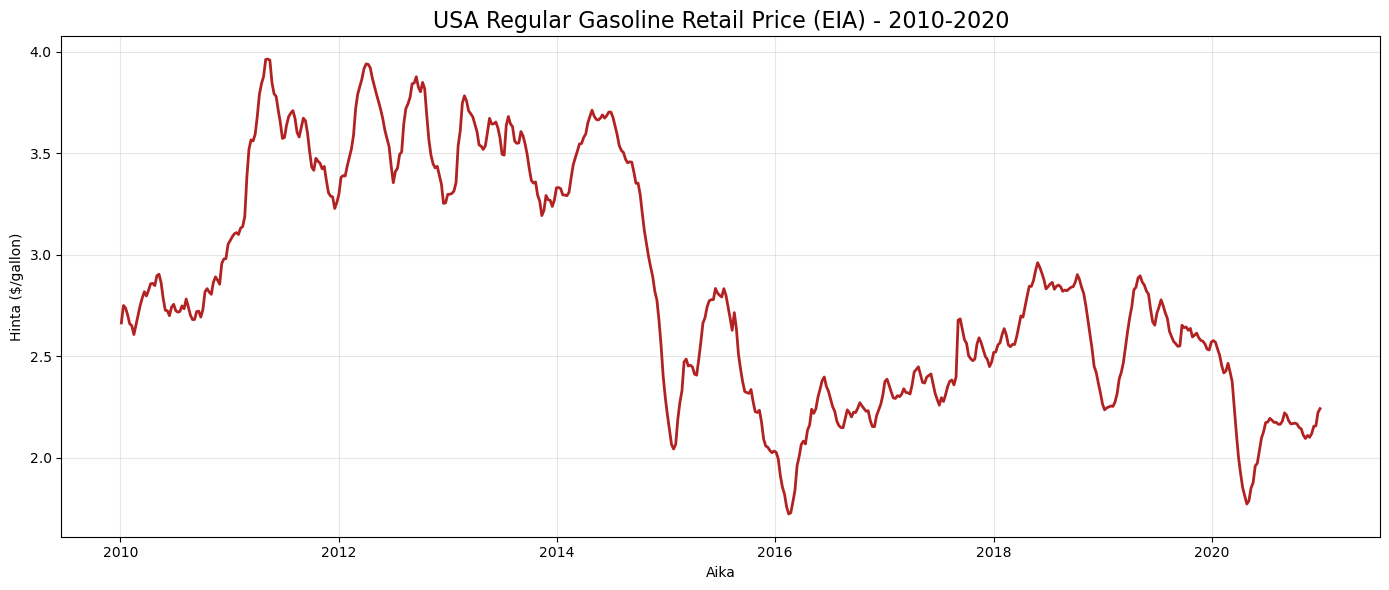

In [20]:
# Haetaan myyntidatan aikaväli (min/max vuodet) 
min_year = df.select(pl.col("listed_date").dt.year().min()).item()
max_year = df.select(pl.col("listed_date").dt.year().max()).item()

# Tehdään kopio bensiinidatasta piirtämistä varten
df_b = df_gas.copy()
df_b["gas_price"] = df_b["value"].astype(float)     # muutetaan hinta floattiin
df_b["date"] = pd.to_datetime(df_b["period"])       # muutetaan period -> datetime

# Rajataan bensiinidatan aikajänne samoihin vuosiin kuin myyntidata -> ei näytä bensahinta-aikasarjan ulkopuolisia vuosia
df_b = df_b[(df_b["date"].dt.year >= min_year) & (df_b["date"].dt.year <= max_year)]


plt.figure(figsize=(14, 6))
plt.plot(df_b["date"], df_b["gas_price"], color="firebrick", linewidth=2)

plt.title(f"USA Regular Gasoline Retail Price (EIA) - {min_year}-{max_year}", fontsize=16)
plt.xlabel("Aika")
plt.ylabel("Hinta ($/gallon)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Bensiinin hinta -korrelaatiot

Bensiinin hinnan ja myyntiajan välinen 0.62 korrelaatio osoittaa vahvan yhteyden: korkeampi bensa -> pidempi myyntiaika.

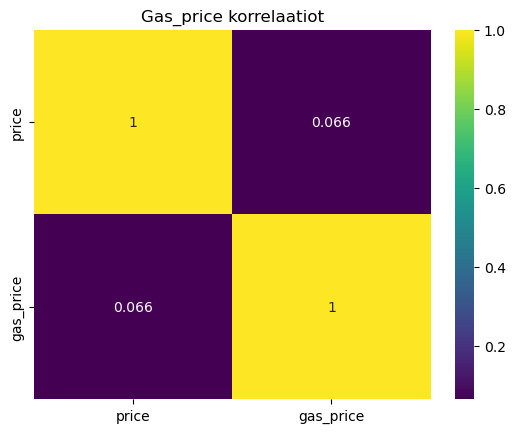

In [21]:
cols = ["price","gas_price"]
sns.heatmap(df.select(cols).to_pandas().corr(), annot=True, cmap="viridis")
plt.title("Gas_price korrelaatiot")
plt.show()

### Label-enkoodaus kategorisille muuttujille
#### -> Tehdäänkin vasta Phase 4:ssa Catboostin vuoksi

In [22]:
# # Lista sarakkeista, jotka muutetaan kategorisista numeerisiksi
# categorical_cols = [
#     # Perus kategoriat
#     "make_name",
#     "model_name",
#     "body_type",
#     "engine_type",
#     "fuel_type",
#     "wheel_system",
#     "trans_group",
#     "listed_season",
#     "listed_month",
#     "listed_weekday", 
#     "age_bin",
#     "mileage_bin",
#     "GEOID",
#     "STATEFP",
# ]

# # Muutetaan kukin sarake:
# # 1) Categorical-tyyppiin (sisäinen kategoriataulukko)
# # 2) to_physical(): palauttaa kategorian numeerisen id-koodin (int)
# df = df.with_columns([
#     pl.col(col).cast(pl.Categorical).to_physical().alias(col)
#     for col in categorical_cols
# ])

### Poistetaan tarpeettomat sarakkeet ennen splittiä

In [23]:
df = df.drop([
    "listed_date", # käytetty km_per_year ja age_bin laskemiseen ja kausi-featureihin
    "transmission_display", # korvattu trans_group:lla
    "length", # käytetty power_density
    "major_options", # string, korvattu opt_* varuste-flageilla
    "NAME", # county-nimi ei hyödytä mallia
    "month_start", # bensiinin hinnan joinin apukenttä
])

### Korjataan virheelliset äärettömät arvot: muutetaan inf → null ja täytetään 0:lla

Jos jokin laskutoimitus menee pieleen, esim. jako nollalla, syntyy inf-arvoja. Nollataan ne, jotta mallille ei päädy mahdottomia numeroita.

In [24]:
# Korvataan virheelliset arvot kaikissa sarakkeissa:
# numeeriset: NaN, null ja ±inf → 0
# muut (teksti jne.): null → ""
df = df.with_columns([
    pl.when(pl.col(c).is_infinite()).then(pl.lit(0.0))
      .otherwise(pl.col(c).fill_nan(0).fill_null(0))
      .alias(c)
    if dtype.is_numeric()
    else pl.col(c).fill_null("").alias(c)
    for c, dtype in zip(df.columns, df.dtypes)
])

# 🔀 Train/test-split

In [25]:
# Satunnainen 80/20 split
pdf = df.to_pandas()
train_pdf, test_pdf = train_test_split(pdf, test_size=0.2, random_state=42)
train_df = pl.from_pandas(train_pdf)
test_df  = pl.from_pandas(test_pdf)

print(f"Train: {len(train_df):,} riviä")
print(f"Test:  {len(test_df):,} riviä")

# Tarkistetaan jakaumat
print(f"\nHintojen keskiarvo:")
print(f"  Train: {train_df['price'].mean():,.0f}")
print(f"  Test:  {test_df['price'].mean():,.0f}")

Train: 2,166,272 riviä
Test:  541,568 riviä

Hintojen keskiarvo:
  Train: 29,283
  Test:  29,307


In [26]:
# # GroupKFold hylättiin koska se jakaa datan niin että tietyt merkki+malli-yhdistelmät
# # ovat vain trainissa tai vain testissä - tämä tekee aggregaattifeaturesista (brand_model_avg_price,
# # model_avg_km) käyttökelvottomia testidatalle, koska ne lasketaan train-datasta eikä
# # testissä ole vastaavia yhdistelmiä. Satunnainen split on realistisempi, koska oikeassa
# # käytössä malli ennustaa tuttuja merkkejä/malleja.

# # Ryhmä = merkki + malli yhdistettynä
# df = df.with_columns(
#     pl.concat_str(
#         [pl.col("make_name"), pl.col("model_name")],
#         separator="_"
#     ).alias("brand_model")
# )

# # GroupKFold — 5 foldia = 80/20 jako
# gkf = GroupKFold(n_splits=5)

# # GroupKFold vaatii numpy-arrayn ryhmistä
# groups = df["brand_model"].to_numpy()

# # Otetaan ensimmäinen fold käyttöön
# for train_idx, test_idx in gkf.split(X=df, y=None, groups=groups):
#     train_df = df[train_idx.tolist()]
#     test_df  = df[test_idx.tolist()]
#     break

# print(f"Train: {len(train_df):,} riviä")
# print(f"Test:  {len(test_df):,} riviä")

# # Varmistetaan ettei vuotoa - pitää olla 0
# train_models = set(train_df["brand_model"].to_list())
# test_models  = set(test_df["brand_model"].to_list())
# print(f"Yhteisiä brand_model-yhdistelmiä: {len(train_models & test_models)}")

# ⚠️ Train/test-splitin jälkeen suoritettavat

### Poistetaan hinta-, kilometri- ja hevosvoimajakaumien ääripäät **ainoastaan opetusdatasta** käyttämällä 1%–99% kvanttiilejä (Tehtävä ennen aggregaatteja!)

In [27]:
# Tarkistetaan paljonko rivejä poistuisi eri rajoilla
for col in ["price", "mileage", "horsepower"]:
    q1 = train_df[col].quantile(0.01)
    q99 = train_df[col].quantile(0.99)
    n = train_df.filter(
        (pl.col(col) < q1) | (pl.col(col) > q99)
    ).height
    print(f"{col}: alle 1% tai yli 99% → {n:,} riviä ({n/train_df.height*100:.1f}%)")

price: alle 1% tai yli 99% → 42,862 riviä (2.0%)
mileage: alle 1% tai yli 99% → 21,663 riviä (1.0%)
horsepower: alle 1% tai yli 99% → 40,855 riviä (1.9%)


In [28]:
print(df['price'].quantile([0.01, 0.99]))

print(f"Rivejä joiden hinta yli 81289: {(df['price'] > 81289).sum()}")
print(f"Rivejä joiden hinta alle 4500: {(df['price'] < 4500).sum()}")



[4500.0, 81289.0]
Rivejä joiden hinta yli 81289: 27078
Rivejä joiden hinta alle 4500: 26534



Muutettu markdowniksi, ei poisteta. Ihan merkittävä parannus tuloksiin näiden arvojen kanssa.


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols = ["price", "mileage", "horsepower"]

# Ennen outlierien poistoa
for i, col in enumerate(cols):
    axes[0, i].hist(train_df[col].to_numpy(), bins=100, color="#378ADD")
    axes[0, i].set_title(f"{col} - ennen")

# ══════ Outlierit pois (1%–99% kvanttiili) ══════
for col in cols:
    q1  = train_df[col].quantile(0.01)
    q99 = train_df[col].quantile(0.99)
    train_df = train_df.filter(pl.col(col).is_between(q1, q99))

# Jälkeen
for i, col in enumerate(cols):
    axes[1, i].hist(train_df[col].to_numpy(), bins=100, color="#1D9E75")
    axes[1, i].set_title(f"{col} - jälkeen")

plt.suptitle("Outlierien poisto - ennen ja jälkeen")
plt.tight_layout()
plt.show()
print(f"Jäljellä: {train_df.height:,} riviä")

### Lasketaan markkina-tason aggregaatit **ainoastaan opetusdatasta** ja liitetään ne sen jälkeen sekä train- että test-dataan

In [29]:

# Poistettu "daysonmarket" liittyvät aggrekaatiot


# ══════ 1. brand_model ══════
train_df=train_df.with_columns(
pl.concat_str(
        [pl.col("make_name"), pl.col("model_name")],
separator="_"
    ).alias("brand_model")
)
test_df=test_df.with_columns(
pl.concat_str(
        [pl.col("make_name"), pl.col("model_name")],
separator="_"
    ).alias("brand_model")
)

# ══════ 2. LOO FEATURES (TRAIN ONLY) ══════
# --- county_avg_price (LOO) ---
train_df=train_df.with_columns([
pl.when(pl.col("price").count().over("GEOID") >1)
.then(
        (pl.col("price").sum().over("GEOID") -pl.col("price")) /
        (pl.col("price").count().over("GEOID") -1)
    )
.otherwise(None)
.alias("county_avg_price")
])

# --- brand_model_avg_price (LOO) ---
train_df=train_df.with_columns([
pl.when(pl.col("price").count().over("brand_model") >1)
.then(
        (pl.col("price").sum().over("brand_model") -pl.col("price")) /
        (pl.col("price").count().over("brand_model") -1)
    )
.otherwise(None)
.alias("brand_model_avg_price")
])



# ══════ 3. NORMAL AGGREGATES FOR TEST ══════
# brand_model_avg_price
brand_avg= (
train_df.group_by("brand_model")
.agg(pl.col("price").mean().alias("brand_model_avg_price"))
)
# model_avg_km (ei tarvitse LOO)
model_avg_km= (
train_df.group_by(["make_name", "model_name"])
.agg(pl.col("mileage").mean().alias("model_avg_km"))
)

# county aggregaatit
county_agg= (
train_df.group_by("GEOID")
.agg([
pl.col("price").mean().alias("county_avg_price")
    ])
)

# ══════ 4. JOIN TEST DATAAN ══════
test_df=test_df.join(county_agg, on="GEOID", how="left")
test_df=test_df.join(brand_avg, on="brand_model", how="left")
test_df=test_df.join(model_avg_km, on=["make_name", "model_name"], how="left")


# ══════ 5. TRAIN: LISÄÄ PUUTTUVAT EI-LOO FEATURES ══════
train_df=train_df.join(model_avg_km, on=["make_name", "model_name"], how="left")

# ══════ 6. CLEANUP ══════
train_df=train_df.drop(["brand_model"])
test_df=test_df.drop(["brand_model"])

print("LOO aggregaatit lisätty oikein (ei leakagea)")

LOO aggregaatit lisätty oikein (ei leakagea)


### Data sample

In [30]:
df.sample(n=10, shuffle=True)

body_type,daysonmarket,engine_displacement,engine_type,mileage,fuel_type,horsepower,latitude,longitude,make_name,model_name,price,wheel_system,year,mileage_missing,is_ev,length_missing,opt_backup_camera,opt_bluetooth,opt_alloy_wheels,opt_heated_seats,opt_navigation,opt_sunroof,opt_remote_start,opt_carplay,opt_android_auto,opt_leather_seats,opt_blind_spot,opt_parking_sensors,opt_adaptive_cruise,opt_lane_departure,opt_cross_traffic,opt_third_row,opt_tow_package,opt_multi_zone,opt_premium_audio,opt_cold_weather,opt_heat_package,opt_off_road,trans_group,listed_season,listed_month,listed_weekday,is_weekend,km_per_year,hp_per_liter,power_density,car_age,age_bin,mileage_bin,options_count,luxury_flag,GEOID,STATEFP,gas_price
str,f64,f64,str,f64,str,f64,f64,f64,str,str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,str,str,f64
"""SUV / Crossover""",73.0,3000.0,"""V6""",31200.0,"""Gasoline""",241.0,35.3516,-80.1642,"""Jeep""","""Grand Cherokee""",27899.0,"""4X2""",2017.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Automatic""","""Summer""",6.0,1.0,0.0,10400.0,0.080333,1.269758,3.0,"""0-3v""","""15k-50k""",9.0,0.0,"""37167""","""37""",2.174
"""SUV / Crossover""",169.0,2000.0,"""I4""",6.0,"""Gasoline""",148.0,38.5189,-90.3429,"""Mazda""","""CX-3""",21189.0,"""AWD""",2020.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Automatic""","""Spring""",3.0,4.0,0.0,6.0,0.074,0.879382,0.0,"""0-3v""","""0-15k""",1.0,0.0,"""29189""","""29""",2.005
"""SUV / Crossover""",26.0,2300.0,"""I4""",161.0,"""Gasoline""",300.0,41.4096,-92.9516,"""Ford""","""Explorer""",46503.0,"""AWD""",2020.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Automatic""","""Summer""",8.0,6.0,1.0,161.0,0.130435,1.509054,0.0,"""0-3v""","""0-15k""",1.0,0.0,"""19125""","""19""",2.222
"""SUV / Crossover""",1.0,2400.0,"""I4""",12869.0,"""Gasoline""",180.0,42.116,-71.0303,"""Jeep""","""Compass""",19995.0,"""4WD""",2018.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Automatic""","""Fall""",9.0,2.0,0.0,6434.5,0.075,1.040462,2.0,"""0-3v""","""0-15k""",3.0,0.0,"""25021""","""25""",2.169
"""SUV / Crossover""",42.0,3500.0,"""V6""",5.0,"""Gasoline""",295.0,33.7365,-117.989,"""INFINITI""","""QX60""",45328.0,"""FWD""",2020.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""CVT""","""Summer""",8.0,6.0,1.0,5.0,0.084286,1.470588,0.0,"""0-3v""","""0-15k""",2.0,0.0,"""06059""","""06""",2.222
"""Sedan""",52.0,2500.0,"""I4""",77165.0,"""Gasoline""",182.0,39.1439,-119.768,"""Nissan""","""Altima""",14495.0,"""FWD""",2017.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Automatic""","""Summer""",7.0,2.0,0.0,25721.666667,0.0728,0.948411,3.0,"""0-3v""","""50k-100k""",3.0,0.0,"""32510""","""32""",2.175
"""SUV / Crossover""",203.0,2400.0,"""I4""",6.0,"""Gasoline""",180.0,29.9117,-95.6118,"""Jeep""","""Cherokee""",23591.0,"""FWD""",2020.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Automatic""","""Winter""",2.0,5.0,1.0,6.0,0.075,0.989011,0.0,"""0-3v""","""0-15k""",6.0,0.0,"""48201""","""48""",2.466
"""Pickup Truck""",6.0,5400.0,"""V8""",119876.0,"""Gasoline""",320.0,40.4271,-74.1051,"""Ford""","""F-150""",13980.0,"""4WD""",2010.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""Automatic""","""Fall""",9.0,5.0,1.0,11987.6,0.059259,1.381096,10.0,"""8+v""","""100k+""",0.0,0.0,"""34025""","""34""",2.169
"""Sedan""",60.0,3500.0,"""V6""",14284.0,"""Gasoline""",290.0,39.9429,-74.9811,"""Acura""","""TLX""",28681.0,"""FWD""",2018.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.

### Train ja test -datan tallennus

In [31]:
# Pakota test_df:n sarakejärjestys samaksi kuin train_df:llä
test_df = test_df.select(train_df.columns)

# Tallennetaan esikäsitelty train- ja test-data
train_df.write_parquet(DATA_PATH / "train.parquet")
test_df.write_parquet(DATA_PATH / "test.parquet")
print(f"Train tallennettu: {train_df.height:,} riviä, {train_df.width} saraketta")
print(f"Test tallennettu:  {test_df.height:,} riviä, {test_df.width} saraketta")

Train tallennettu: 2,166,272 riviä, 58 saraketta
Test tallennettu:  541,568 riviä, 58 saraketta
